# 03 - Anomaly detection

Models trained on normal traffic only, so they never see an attack before test time.
Same splits, same threshold rule (1% FPR on validation) and same `results.json` as `02_supervised`, so the numbers are directly comparable.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline

from netad.data import load_unsw_frame, overlap_with_train, distinct_rows, train_val_split, CATEGORICAL, FEATURES
from netad.preprocessing import build_preprocessor
from netad.evaluation import (
    FIGURES_DIR, evaluate_binary, choose_threshold, evaluate_test, save_result, results_table,
)

In [3]:
train_df = load_unsw_frame("train")
test_df = load_unsw_frame("test")

X_test = test_df[FEATURES]
y_test = test_df["label"]
y_test_multi = test_df["attack_cat"]
unseen = ~overlap_with_train(train_df, test_df)
distinct = distinct_rows(test_df)

X_tr, X_val, y_tr, y_val = train_val_split(train_df, "label")
val_categories = train_df.loc[X_val.index, "attack_cat"]
X_normal = X_tr[y_tr == 0]

MAX_FPR = 0.01

len(X_normal), len(X_tr), len(X_val), len(X_test)

(41367, 80752, 20189, 82332)

Training uses only the normal rows of the training part. The preprocessor is fitted on them too, so protocols and services that only attacks use end up in the "infrequent" one-hot column.

Validation keeps both classes. With an FPR budget the threshold is set by how normal validation flows score (about their 99th percentile), attack labels don't move it.

## Isolation Forest

Random trees that split on random features at random values. A flow that gets isolated after few splits is unusual. Anomaly score: `-score_samples` (higher = more anomalous). `contamination` is not used, the threshold comes from validation like for the other models.

A few settings are compared on validation partial ROC-AUC (FPR <= 1%): how many normal flows each tree is built on (`max_samples`, 1.0 = all of them) and whether the one-hot columns are used, since random splits on 0/1 columns isolate little. This uses the attack labels of validation, so the choice is not completely label free; the grid is kept small for that reason.

In [4]:
def anomaly_scores(model, X):
    return -model.score_samples(X)


columns = {"all": None, "numeric only": CATEGORICAL}

iforest = {}
for max_samples in [256, 1024, 4096, 16384, 1.0]:
    for cols, exclude in columns.items():
        model = make_pipeline(
            build_preprocessor(exclude=exclude),
            IsolationForest(n_estimators=300, max_samples=max_samples, random_state=42, n_jobs=-1),
        ).fit(X_normal)
        s_val = anomaly_scores(model, X_val)
        iforest[(len(X_normal) if max_samples == 1.0 else max_samples, cols)] = {
            "model": model,
            "params": {"n_estimators": 300, "max_samples": max_samples, "excluded": exclude or []},
            "val_pauc": roc_auc_score(y_val, s_val, max_fpr=MAX_FPR),
            "val_roc_auc": roc_auc_score(y_val, s_val),
        }

pd.DataFrame(
    {k: {"val pAUC": v["val_pauc"], "val ROC-AUC": v["val_roc_auc"]} for k, v in iforest.items()}
).T.rename_axis(["max_samples", "columns"]).round(4)

val pAUC  val ROC-AUC
max_samples columns                            
256         all             0.4987       0.7665
            numeric only    0.4984       0.8311
1024        all             0.5090       0.7747
            numeric only    0.5026       0.8128
4096        all             0.5187       0.7810
            numeric only    0.5130       0.8068
16384       all             0.5371       0.7926
            numeric only    0.5265       0.8088
41367       all             0.5459       0.7950
            numeric only    0.5352       0.8067

In [5]:
best = max(iforest.values(), key=lambda v: v["val_pauc"])
model = best["model"]
best["params"]

{'n_estimators': 300, 'max_samples': 1.0, 'excluded': []}

In [6]:
s_val = anomaly_scores(model, X_val)
s_test = anomaly_scores(model, X_test)
threshold = choose_threshold(y_val, s_val, "fpr", max_fpr=MAX_FPR)

metrics = {
    "val": evaluate_binary(y_val, s_val, threshold, categories=val_categories),
    **evaluate_test(evaluate_binary, y_test, s_test, unseen, distinct, categories=y_test_multi, threshold=threshold),
}
save_result("IsolationForest", "binary", metrics, {"threshold_mode": "fpr", "max_fpr": MAX_FPR, **best["params"]})

pd.DataFrame({k: {m: v[m] for m in ["recall", "macro_detection", "fpr", "precision", "roc_auc", "pr_auc"]} for k, v in metrics.items()}).T.round(4)

,recall,macro_detection,fpr,precision,roc_auc,pr_auc
val,0.1688,0.2490,0.0100,0.9416,0.7950,0.7993
test,0.6119,0.4764,0.0264,0.9660,0.8811,0.9121
test_unseen,0.5751,0.4333,0.0254,0.9606,0.8708,0.8957
test_distinct,0.2948,0.3786,0.0180,0.9122,0.7961,0.7476


Recall on validation and on test are far apart. Per category, with the share of each category among the attacks:

In [7]:
def per_category(m):
    cats = {c: v for c, v in m["by_category"].items() if c != "Normal"}
    total = sum(v["n"] for v in cats.values())
    return pd.DataFrame({c: {"share of attacks": v["n"] / total, "flagged": v["flagged"]} for c, v in cats.items()}).T


pd.concat({s: per_category(metrics[s]) for s in ["val", "test", "test_distinct"]}, axis=1).round(3)

val                     test          \
               share of attacks flagged share of attacks flagged   
Analysis                  0.011   0.241            0.015   0.885   
Backdoor                  0.010   0.456            0.013   0.909   
DoS                       0.061   0.285            0.090   0.699   
Exploits                  0.380   0.157            0.246   0.358   
Fuzzers                   0.303   0.033            0.134   0.225   
Generic                   0.080   0.864            0.416   0.957   
Reconnaissance            0.130   0.040            0.077   0.096   
Shellcode                 0.022   0.000            0.008   0.000   
Worms                     0.002   0.167            0.001   0.159   

                  test_distinct          
               share of attacks flagged  
Analysis                  0.021   0.825  
Backdoor                  0.016   0.847  
DoS                       0.079   0.391  
Exploits                  0.350   0.174  
Fuzzers                   0.223   0.115  
Generic                   0.168   0.800  
Reconnaissance            0.124   0.096  
Shellcode                 0.017   0.000  
Worms                     0.002   0.159

Scores of normal flows, validation vs test, against the threshold (same check as for the random forest in `02_supervised`):

In [8]:
normal_val = s_val[(y_val == 0).to_numpy()]
normal_test = s_test[(y_test == 0).to_numpy()]

pd.DataFrame({
    "validation": pd.Series(normal_val).quantile([0.5, 0.9, 0.95, 0.99]),
    "test": pd.Series(normal_test).quantile([0.5, 0.9, 0.95, 0.99]),
}).rename_axis("quantile").round(4).assign(threshold=round(threshold, 4))

,validation,test,threshold
quantile,,,
0.50,0.3822,0.3974,0.5574
0.90,0.4493,0.4757,0.5574
0.95,0.4764,0.5079,0.5574
0.99,0.5573,0.6004,0.5574


## Comparison with the supervised models

All binary models in `results.json`, threshold at 1% FPR on validation for each.

- All rows: the traffic as it comes. A DoS really produces many identical flows and each one is an alert, so FPR and alert volume are read here.
- Distinct rows: each feature vector + category once. Counts how many different attack flows a model catches, without a few flows repeated thousands of times weighing in; models are compared here.
- Recall depends on which categories are frequent in the subset, `macro_detection` (mean rate over the 9 attack categories) does not.

In [9]:
cols = ["recall", "macro_detection", "fpr", "precision", "roc_auc"]
pd.concat({subset: results_table("binary", subset, cols) for subset in ["test", "test_unseen", "test_distinct"]}, axis=1).round(3)

test                                           \
                      recall macro_detection    fpr precision roc_auc   
Dummy (prior)          0.000           0.000  0.000     0.000   0.500   
LogisticRegression     0.804           0.749  0.025     0.975   0.968   
RandomForest           0.891           0.882  0.040     0.965   0.982   
HistGradientBoosting   0.920           0.918  0.048     0.959   0.985   
RandomForest (no TTL)  0.886           0.879  0.043     0.962   0.980   
IsolationForest        0.612           0.476  0.026     0.966   0.881   

                      test_unseen                                           \
                           recall macro_detection    fpr precision roc_auc   
Dummy (prior)               0.000           0.000  0.000     0.000   0.500   
LogisticRegression          0.772           0.710  0.023     0.973   0.963   
RandomForest                0.871           0.869  0.037     0.962   0.979   
HistGradientBoosting        0.906           0.910  0.047     0.954   0.983   
RandomForest (no TTL)       0.865           0.864  0.040     0.959   0.977   
IsolationForest             0.575           0.433  0.025     0.961   0.871   

                      test_distinct                                           
                             recall macro_detection    fpr precision roc_auc  
Dummy (prior)                 0.000           0.000  0.000     0.000   0.500  
LogisticRegression            0.631           0.694  0.024     0.943   0.943  
RandomForest                  0.798           0.859  0.039     0.928   0.968  
HistGradientBoosting          0.855           0.904  0.048     0.919   0.973  
RandomForest (no TTL)         0.791           0.855  0.042     0.923   0.965  
IsolationForest               0.295           0.379  0.018     0.912   0.796

Detection rate per attack category, Isolation Forest vs the best supervised model (random forest), on all test rows and on the distinct ones:

In [10]:
by_category = pd.DataFrame({
    (name, subset): {c: v["flagged"] for c, v in results_table("binary", subset, ["by_category"]).loc[name, "by_category"].items()}
    for name in ["RandomForest", "IsolationForest"]
    for subset in ["test", "test_distinct"]
})
by_category.round(3)

RandomForest               IsolationForest              
                       test test_distinct            test test_distinct
Analysis              0.914         0.870           0.885         0.825
Backdoor              0.988         0.980           0.909         0.847
DoS                   0.957         0.919           0.699         0.391
Exploits              0.942         0.928           0.358         0.174
Fuzzers               0.382         0.303           0.225         0.115
Generic               0.992         0.976           0.957         0.800
Normal                0.040         0.039           0.026         0.018
Reconnaissance        0.962         0.954           0.096         0.096
Shellcode             0.870         0.870           0.000         0.000
Worms                 0.932         0.932           0.159         0.159

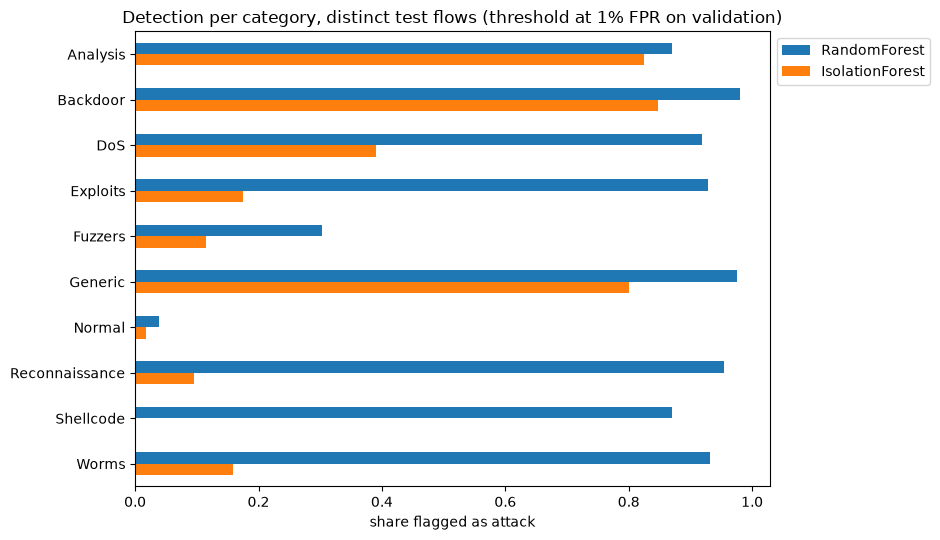

In [11]:
ax = by_category.xs("test_distinct", axis=1, level=1).plot.barh(figsize=(9.5, 5.5))
ax.invert_yaxis()
ax.set_xlabel("share flagged as attack")
ax.set_title("Detection per category, distinct test flows (threshold at 1% FPR on validation)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.figure.tight_layout()
ax.figure.savefig(FIGURES_DIR / "anomaly_detection_by_category.png", dpi=120)
plt.show()

## Conclusions

1. **Isolation Forest is far behind the supervised models.** On distinct test rows, where models are compared, it catches 29% of attacks (`macro_detection` 0.38) against 80% (0.86) for the random forest, ROC-AUC 0.80 vs 0.97. On all test rows: 61% at 2.6% FPR vs 89% at 4.0%. Expected: the random forest was shown what attacks look like, Isolation Forest only knows normal traffic.
2. **Each recall figure describes a different attack mix.** Recall is 17% on validation, 29% on distinct test rows and 61% on all test rows. Generic, the category it catches best, is 8%, 17% and 42% of the attacks in those three sets. `macro_detection`, which gives each category the same weight, moves much less: 0.25, 0.38, 0.48. What is left comes from within categories: repeated attack flows are easier to isolate (DoS 39% distinct vs 70% on all rows), and test scores higher than validation overall, normal flows included (point 4).
3. **It catches attacks that look unusual, not the ones that blend in.** On distinct test rows: Backdoor 85%, Analysis 83%, Generic 80%, DoS 39%, Exploits 17%, Fuzzers 12%, Reconnaissance 10%, Shellcode 0%. The random forest stays above 87% on all of them except Fuzzers (30%).
4. **The FPR shifts on test here too, less than for the random forest.** 1% on validation becomes 2.6% on test (1.8% on distinct normal flows), against 4.0% for the random forest. 99th percentile of the normal scores: 0.557 on validation, 0.600 on test.
5. **Settings.** More normal flows per tree helps steadily (validation pAUC 0.499 with 256, the default, 0.546 with all 41,367). Dropping the one-hot columns raises the full ROC-AUC on validation but lowers pAUC, which is the region where the alert threshold sits. Even the best setting stays close to 0.5 pAUC: below 1% FPR it ranks the validation attacks barely better than chance.
6. **Not answered yet:** whether it catches attack types a supervised model has never seen, which is what anomaly detection is for. That is the leave-one-attack-out experiment, run together with the autoencoder: the left-out category is removed from train and validation (so it plays no part in the setting or threshold choice) and detection is measured on its distinct test rows.